# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/mypkg'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


##  Batch running of the pipeline

In [ ]:

# Ensure `clustering_pipeline` is available in your environment,
# e.g., `from your_module import clustering_pipeline`

def run_troutpy_pipeline(
    inpath,
    data_filename='data.zarr',
    output_filename='data_processed.zarr',
    output_filtered_filename='data_processed_filtered.zarr',
    figures_dir='figures',
    # sainsc parameters
    binsize=3,
    celltype_key='leiden',
    background_filter=0.4,
    gaussian_kernel_key=2.0,
    n_threads=16,
    # extracellular definition
    percentile_threshold=20,
    # aggregation
    square_size_transcripts=10,
    # spatial stats
    n_neighbors=10,
    square_size_variability=20,
    threshold_colocalized=1,
    # exRNA filter
    min_logfoldratio_over_noise=0,
    # source scoring
    lambda_decay=0.1,
    diffusion_distance_key='distance'
):
    """
    Execute a full Troutpy spatial transcriptomics pipeline on the provided dataset.

    Parameters
    ----------
    inpath : str
        Path to the folder containing `data.zarr`.
    data_filename : str, optional
        Name of the input .zarr file (default 'data.zarr').
    output_filename : str, optional
        Name for the first processed output .zarr (default 'data_processed.zarr').
    output_filtered_filename : str, optional
        Name for the filtered output .zarr (default 'data_processed_filtered.zarr').
    figures_dir : str, optional
        Subdirectory under `inpath` to save figures (default 'figures').
    binsize : int, optional
        Bin size for segmentation_free_sainsc (default 3).
    celltype_key : str, optional
        Key for cell clustering labels (default 'leiden').
    background_filter : float, optional
        Background filter threshold for sainsc (default 0.4).
    gaussian_kernel_key : float, optional
        Gaussian kernel sigma for sainsc (default 2.0).
    n_threads : int, optional
        Threads for parallel processing (default 16).
    percentile_threshold : int, optional
        Percentile for extracellular definition (default 20).
    square_size_transcripts : int, optional
        Square size for transcript aggregation (default 10).
    n_neighbors : int, optional
        Number of neighbors for spatial stats (default 10).
    square_size_variability : int, optional
        Square size for spatial variability (default 20).
    threshold_colocalized : int, optional
        Threshold for spatial colocalization (default 1).
    min_logfoldratio_over_noise : float, optional
        Minimum log-fold ratio to filter exRNA (default 0).
    lambda_decay : float, optional
        Lambda decay for source scoring (default 0.1).
    diffusion_distance_key : str, optional
        Key for distance in diffusion assessment (default 'distance').
    """
    # Prepare figure directory
    figures_path = os.path.join(inpath, figures_dir)
    os.makedirs(figures_path, exist_ok=True)

    # Load data
    sdata = sd.read_zarr(os.path.join(inpath, data_filename))

    # 1. Clustering cells
    clustering_pipeline(sdata)

    # 2. Segmentation-free SAINSc
    troutpy.pp.segmentation_free_sainsc(
        sdata,
        binsize=binsize,
        celltype_key=celltype_key,
        background_filter=background_filter,
        gaussian_kernel_key=gaussian_kernel_key,
        n_threads=n_threads
    )
    troutpy.pl.histogram(
        sdata,
        x='cosine_similarity',
        hue='overlaps_cell',
        save=True,
        figures_path=figures_path
    )

    # 3. Extracellular definition
    troutpy.pp.define_extracellular(
        sdata,
        layer='transcripts',
        method='sainsc',
        copy=False,
        percentile_threshold=percentile_threshold
    )

    # 4. Plots: crosstab, pie, heatmap
    troutpy.pl.crosstab(
        sdata,
        yvar='extracellular',
        xvar='overlaps_cell',
        normalize=False,
        cmap='troutpy',
        kind='barh',
        stacked=True,
        save=True,
        figures_path=figures_path
    )
    troutpy.pl.pie(
        sdata,
        groupby='match_cell_signature',
        group_key='overlaps_cell',
        palette='troutpy',
        figures_path=figures_path
    )
    troutpy.pl.crosstab(
        sdata,
        xvar='extracellular',
        yvar='overlaps_cell',
        normalize=True,
        cmap='Aquas',
        kind='heatmap',
        stacked=True,
        save=True,
        figures_path=figures_path
    )

    # 5. Aggregate transcripts
    troutpy.pp.aggregate_extracellular_transcripts(
        sdata,
        gene_key='gene',
        square_size=square_size_transcripts
    )

    # 6. Spatial statistics
    troutpy.tl.quantify_overexpression(
        sdata,
        codeword_key='control_probe',
        control_codewords=[True],
        gene_key='gene'
    )
    troutpy.tl.extracellular_enrichment(sdata, gene_key='gene')
    troutpy.tl.spatial_variability(
        sdata,
        gene_key='gene',
        n_neighbors=n_neighbors,
        square_size=square_size_variability
    )
    troutpy.tl.in_out_correlation(sdata, n_neighbors=n_neighbors)
    troutpy.tl.spatial_colocalization(
        sdata,
        threshold_colocalized=threshold_colocalized,
        copy=False
    )

    # 7. Metric plots
    troutpy.pl.logfoldratio_over_noise(
        sdata,
        test_method='auto',
        palette='troutpy',
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='logfoldratio_over_noise',
        y='extracellular_proportion',
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='in_out_spearmanR',
        y='extracellular_proportion',
        label_top_n_x=10,
        label_bottom_n_x=5,
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='in_out_spearmanR',
        y='moran_I',
        label_top_n_y=5,
        label_bottom_n_y=5,
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='proportion_of_colocalized',
        y='extracellular_proportion',
        label_top_n_x=5,
        label_bottom_n_x=5,
        figures_path=figures_path,
        save=True
    )

    # Save intermediate processed data
    sdata.write(os.path.join(inpath, output_filename), overwrite=True)

    # 8. Filter exRNA and source scoring
    troutpy.pp.filter_xrna(
        sdata,
        min_logfoldratio_over_noise=min_logfoldratio_over_noise,
        gene_key='gene'
    )
    troutpy.tl.compute_source_score(
        sdata,
        layer='transcripts',
        gene_key='gene',
        lambda_decay=lambda_decay,
        copy=False,
        celltype_key=celltype_key
    )

    # 9. Diffusion analysis
    troutpy.tl.assess_diffussion(
        sdata,
        gene_key='gene',
        distance_key=diffusion_distance_key
    )
    troutpy.pl.diffusion_results(
        sdata,
        y_col='-log_ks_pval',
        y_logscale=True,
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='mean_displacement',
        y='extracellular_proportion',
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True
    )
    troutpy.pl.metric_scatter(
        sdata,
        x='mean_displacement',
        y='in_out_spearmanR',
        label_top_n_y=1,
        label_top_n_x=10,
        figures_path=figures_path,
        save=True
    )

    # Save filtered processed data
    sdata.write(os.path.join(inpath, output_filtered_filename), overwrite=True)
    return sdata


In [ ]:
 inpath = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300"
    
sdata = run_troutpy_pipeline(inpath)
    
print(sdata)

Proportion of cells retained after filtering: 99.27%


2025-04-22 10:15:34.427522: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-22 10:15:34.584235: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745309734.654341 1838623 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745309734.673522 1838623 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1745309734.807287 1838623 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

Final adata shape: (22896, 248)


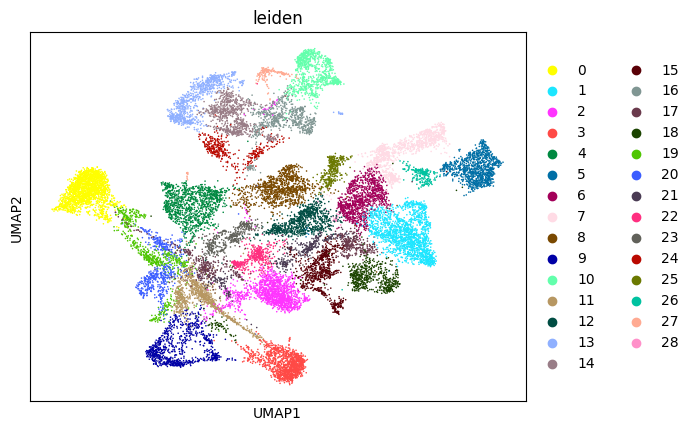

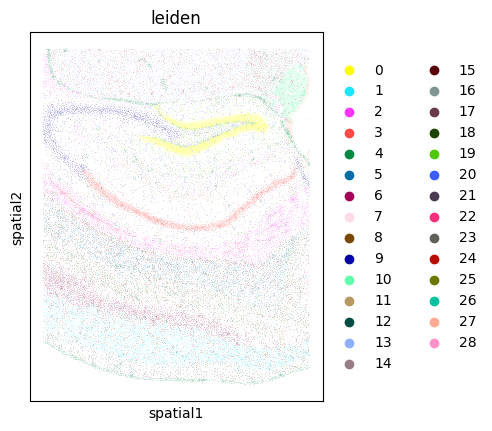

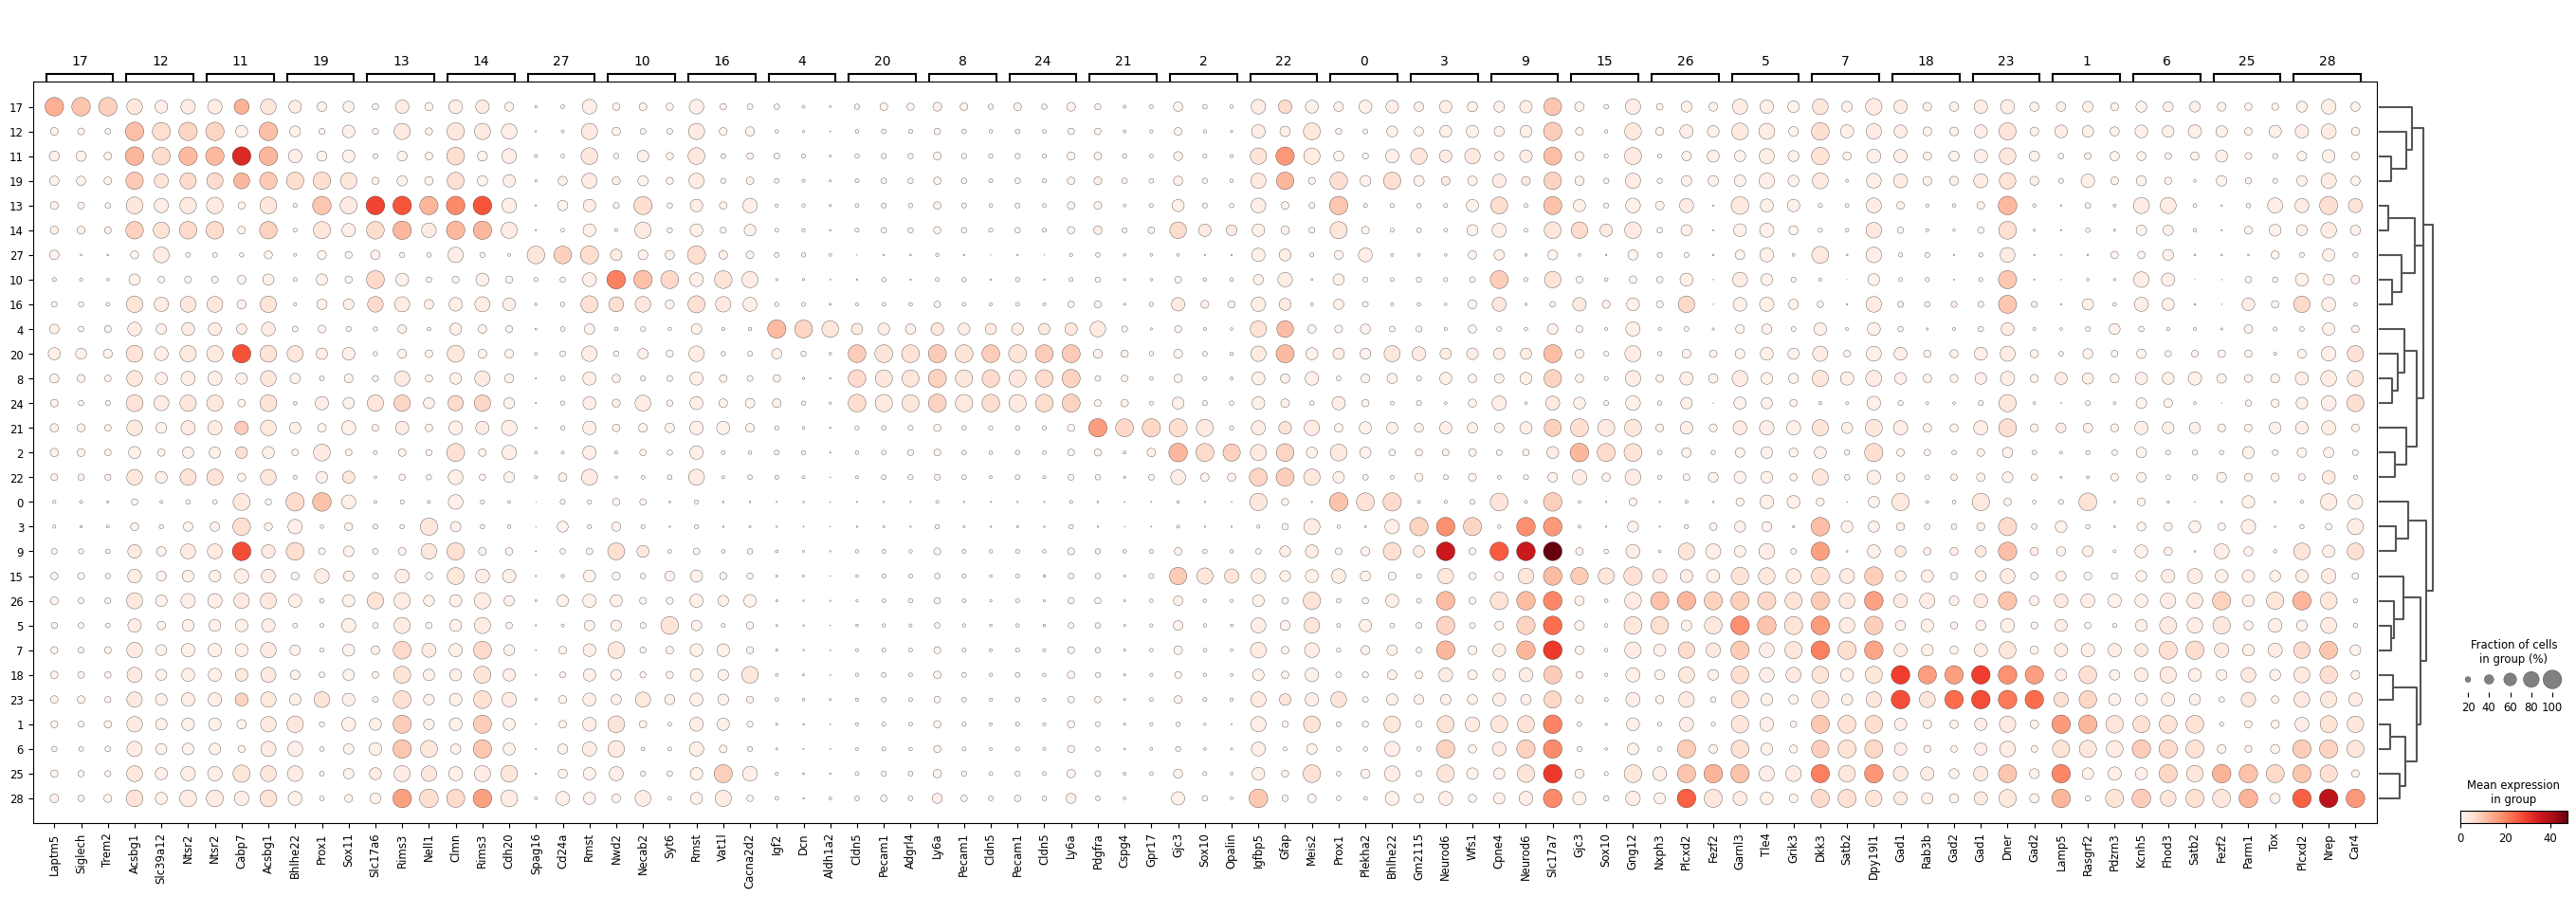

Cosine similarity threshold for extracellular definition: 0.6159874200820923
Added 'xrna_metadata' table with 541 unique genes to the SpatialData object.
Using precomputed segmentation free table


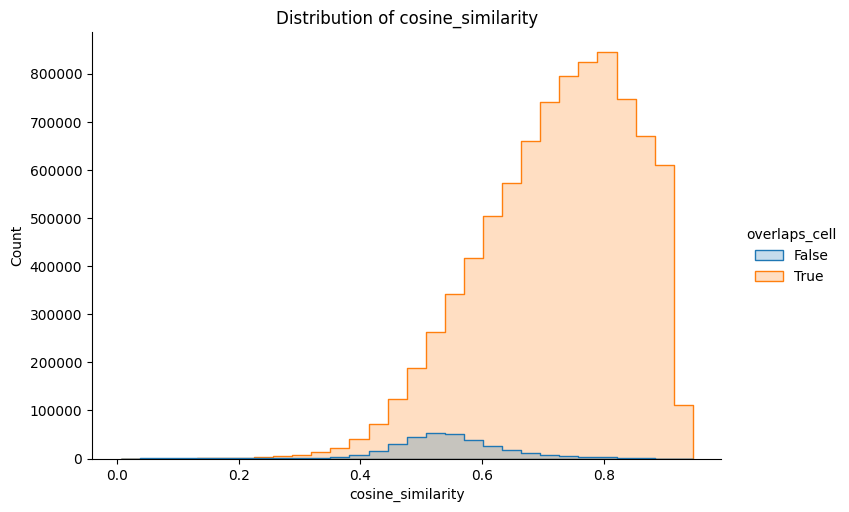

<Figure size 500x500 with 0 Axes>

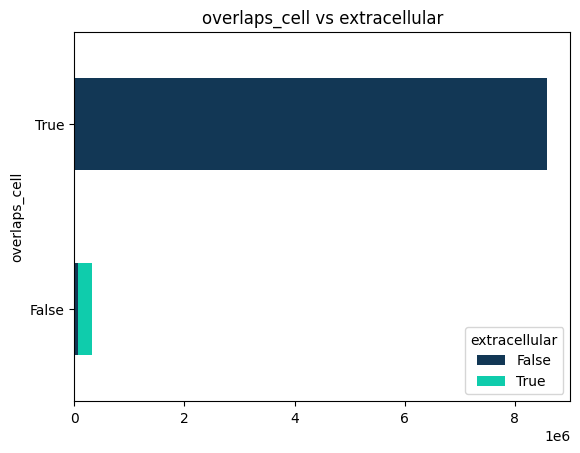

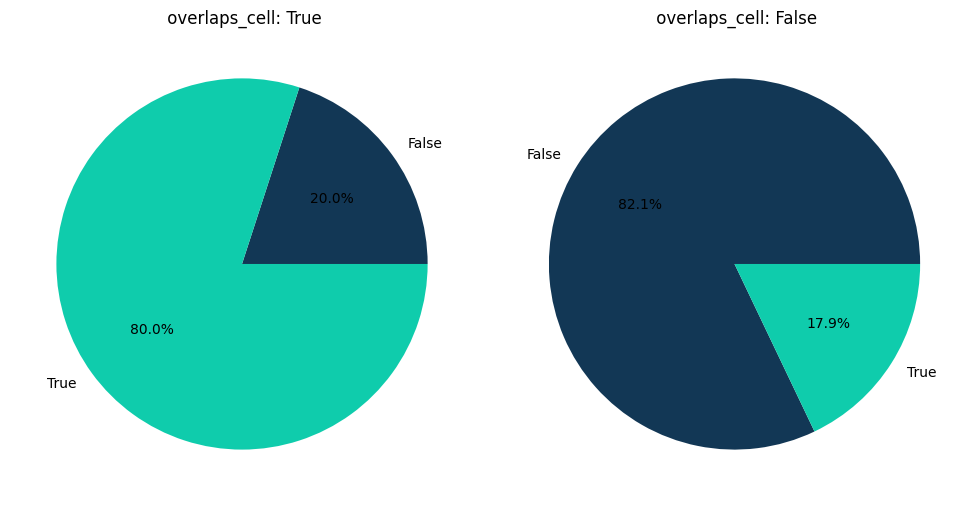

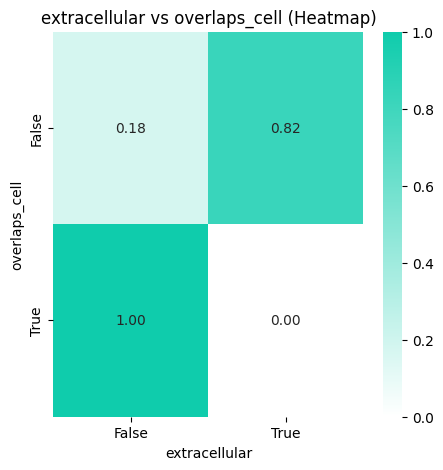

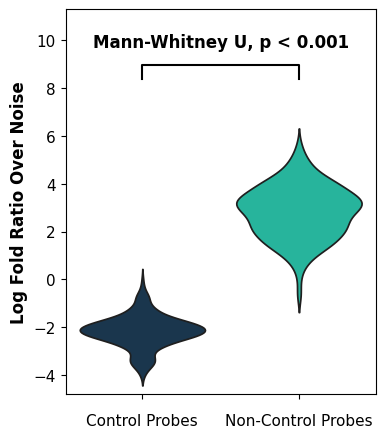

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


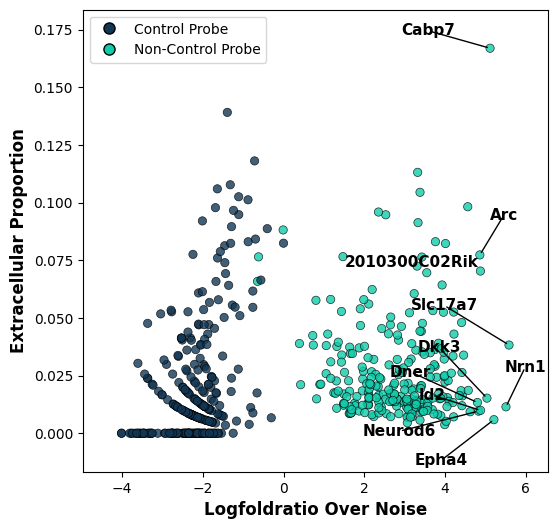

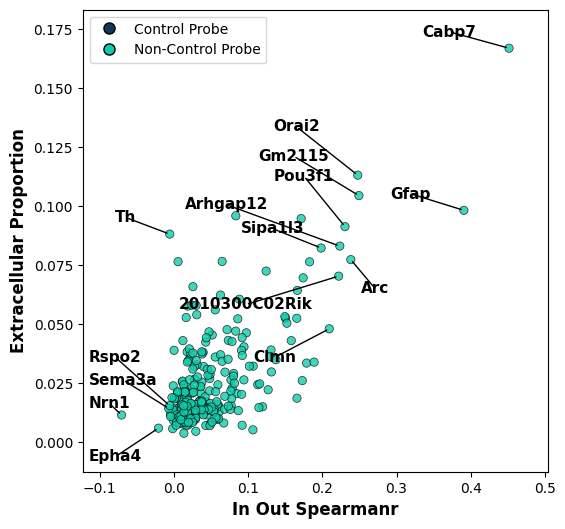

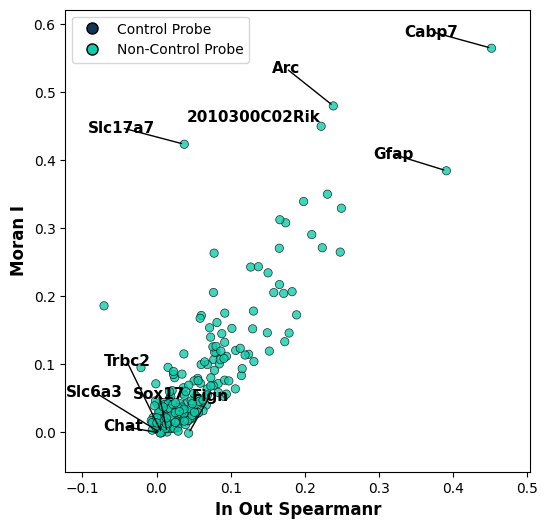

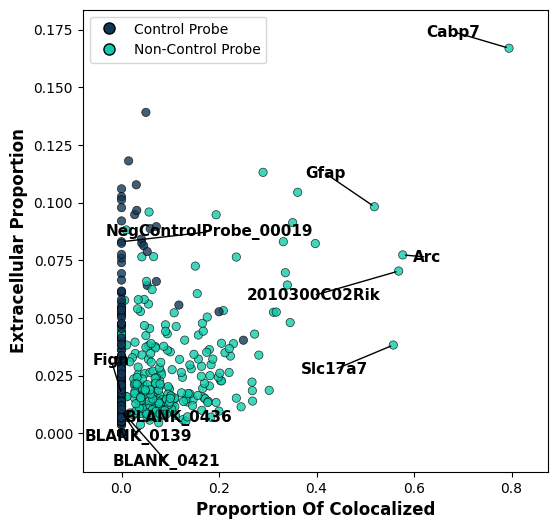

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed.zarr). Please see 
         the documentation of `is_self_contained()` to understand the implications of working with SpatialData     
         objects that are not self-contained.                                                                      
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data.zarr the new file path:                       
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed.zarr                                


Processing genes:  13%|█▎        | 32/245 [00:02<00:18, 11.81it/s]/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `d

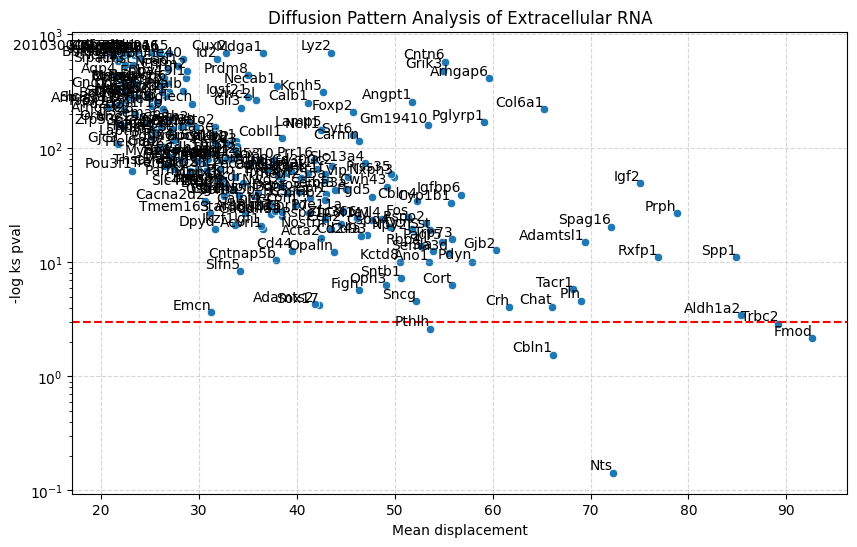

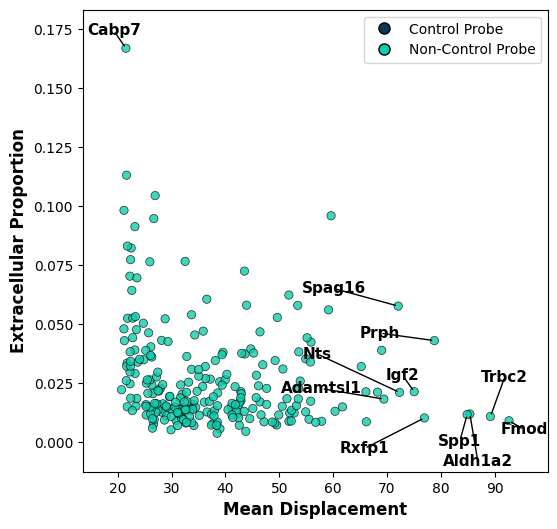

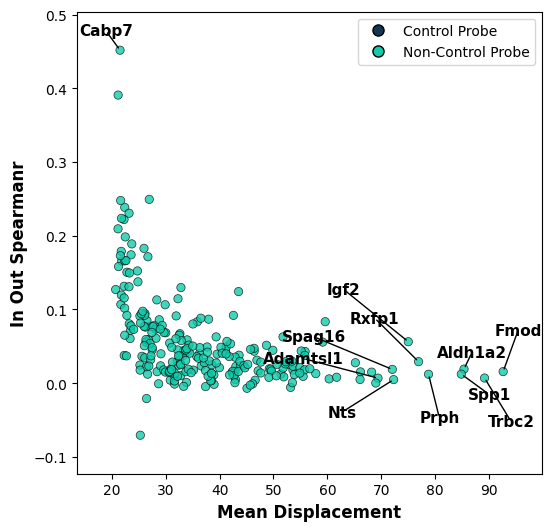

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed_filtered.zarr).   
         Please see the documentation of `is_self_contained()` to understand the implications of working with      
         SpatialData objects that are not self-contained.                                                          
INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed.zarr the new file path:             
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_300/data_processed_filtered.zarr                       


In [2]:
inpath  = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_300" # modify this path

saving_path=os.path.join(inpath,'figures')
if not os.path.exists(saving_path):
    os.makedirs(saving_path)
sdata=sd.read_zarr(os.path.join(inpath,'data.zarr'))

# clustering cells
clustering_pipeline(sdata)

# apply sainsc
troutpy.pp.segmentation_free_sainsc(sdata,binsize=3,celltype_key='leiden',
                                    background_filter=0.4,gaussian_kernel_key=2.0,
                                    n_threads=16)

troutpy.pl.histogram(sdata,x='cosine_similarity',hue='overlaps_cell',save=True,figures_path=saving_path)

# we define what we consider extracellular

troutpy.pp.define_extracellular(sdata,layer = "transcripts",method= "sainsc",copy = False, percentile_threshold = 20)

# Define path for saving figures inside function

troutpy.pl.crosstab(sdata,yvar='extracellular',xvar='overlaps_cell',normalize=False, cmap='troutpy',kind='barh',stacked=True,save=True,figures_path=saving_path)
troutpy.pl.pie(sdata, groupby="match_cell_signature",group_key='overlaps_cell',palette='troutpy',figures_path=saving_path)
troutpy.pl.crosstab(sdata,xvar='extracellular',yvar='overlaps_cell',normalize=True, cmap='Aquas',kind='heatmap',stacked=True,save=True,figures_path=saving_path)

# This is an important step to define bins. Square size might be the most important parameter. TBD what is optimal
troutpy.pp.aggregate_extracellular_transcripts(sdata,gene_key='gene',square_size= 10)

# define spatial statistics
troutpy.tl.quantify_overexpression(sdata,codeword_key="control_probe",control_codewords=[True],gene_key="gene")
troutpy.tl.extracellular_enrichment(sdata,gene_key='gene')
troutpy.tl.spatial_variability(sdata, gene_key="gene", n_neighbors=10, square_size=20)
troutpy.tl.in_out_correlation(sdata,n_neighbors=10) # this is the good one
troutpy.tl.spatial_colocalization(sdata, threshold_colocalized=1, copy=False)
#plotting
troutpy.pl.logfoldratio_over_noise(sdata,test_method="auto",palette='troutpy',figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="logfoldratio_over_noise",y="extracellular_proportion",label_top_n_y=1,label_top_n_x=10,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="in_out_spearmanR",y="extracellular_proportion",label_top_n_x=10,label_bottom_n_x=5,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="in_out_spearmanR",y="moran_I",label_top_n_y=5,label_bottom_n_y=5,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="proportion_of_colocalized",y="extracellular_proportion",label_top_n_x=5,label_bottom_n_x=5,figures_path=saving_path,save=True)
# save
sdata.write(os.path.join(inpath,'data_processed.zarr'),overwrite=True)

# Work only of exRNA that is above noise levels
troutpy.pp.filter_xrna(sdata,min_logfoldratio_over_noise=0,gene_key='gene')
troutpy.tl.compute_source_score(sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="leiden")
# Work on source identification
troutpy.tl.assess_diffussion( sdata, gene_key= "gene", distance_key= "distance")
troutpy.pl.diffusion_results(sdata, y_col='-log_ks_pval',y_logscale=True,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="mean_displacement",y="extracellular_proportion",label_top_n_y=1,label_top_n_x=10,figures_path=saving_path,save=True)
troutpy.pl.metric_scatter(sdata,x="mean_displacement",y="in_out_spearmanR",label_top_n_y=1,label_top_n_x=10,figures_path=saving_path,save=True)
sdata.write(os.path.join(inpath,'data_processed_filtered.zarr'),overwrite=True)